In [4]:
import pandas as pd
from pathlib import Path

# Get the project root directory
project_root = Path.cwd().parent

# Build the complete path to the cleaned dataset
csv_path = project_root / "data" / "processed" / "telco_churn_cleaned.csv"

# Load the dataset
df = pd.read_csv(csv_path)

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Customer Churn Counts:")
print(df["Churn"].value_counts())

print("\nCustomer Churn Percentages:")
print(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

Customer Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer Churn Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


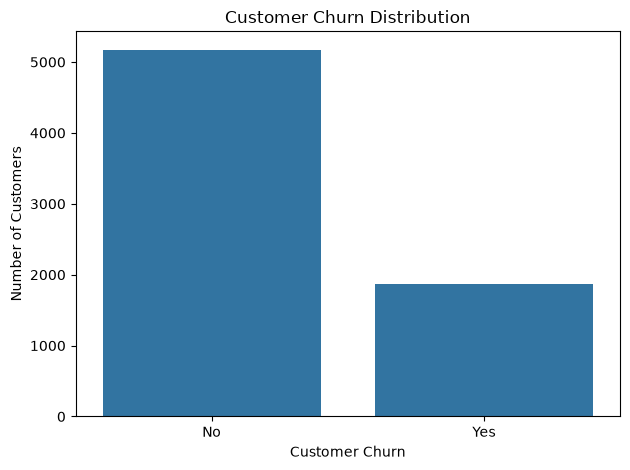

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [7]:
# Calculate churn percentage for each contract type
churn_by_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Percentage by Contract Type:")
display(churn_by_contract.round(2))

Churn Percentage by Contract Type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


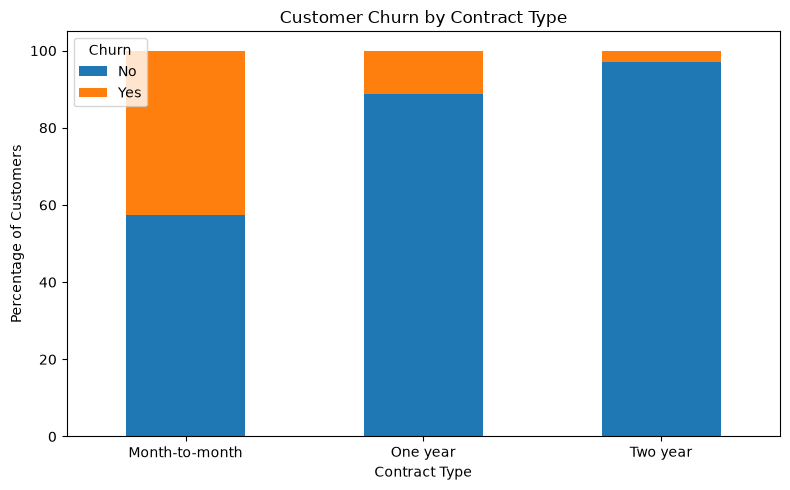

In [8]:
churn_by_contract.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
# Compare tenure for customers who stayed and left
tenure_summary = df.groupby("Churn")["tenure"].agg(
    ["mean", "median", "min", "max"]
)

print("Tenure Summary by Churn:")
display(tenure_summary.round(2))

Tenure Summary by Churn:


,mean,median,min,max
Churn,,,,
No,37.57,38.0,0,72
Yes,17.98,10.0,1,72


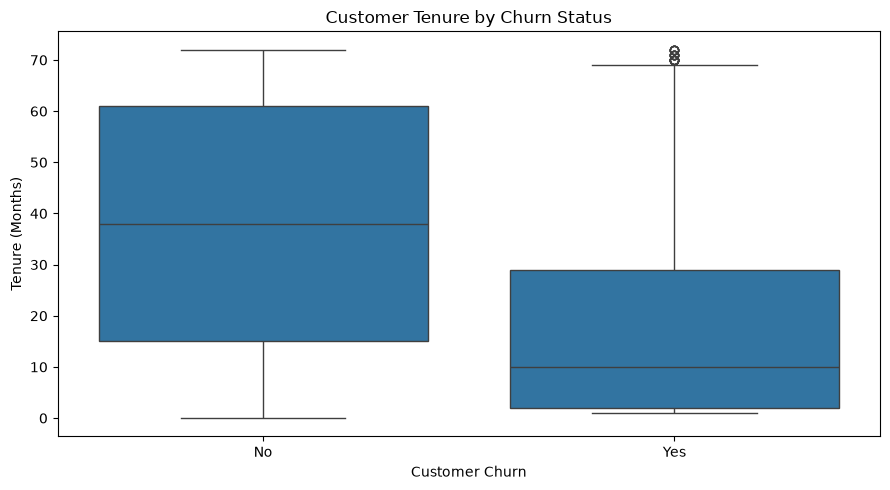

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

In [11]:
# Compare monthly charges for customers who stayed and left
charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "min", "max"]
)

print("Monthly Charges Summary by Churn:")
display(charges_summary.round(2))

Monthly Charges Summary by Churn:


,mean,median,min,max
Churn,,,,
No,61.27,64.43,18.25,118.75
Yes,74.44,79.65,18.85,118.35


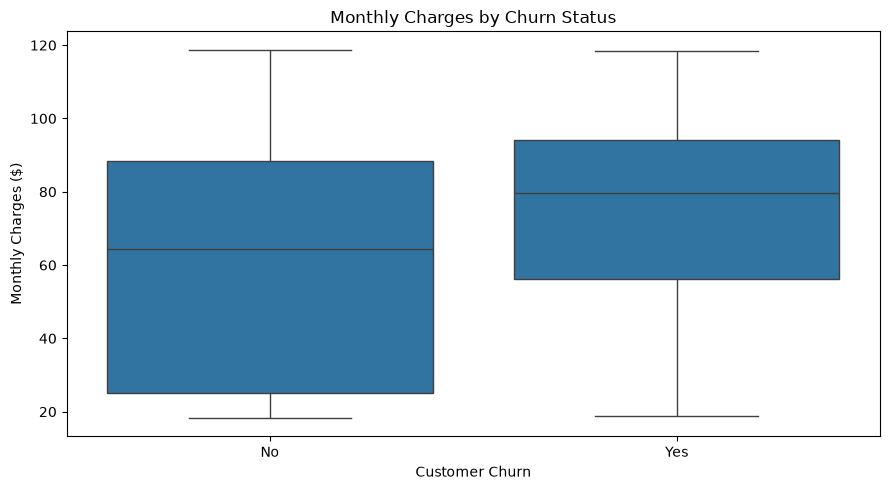

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges ($)")

plt.tight_layout()
plt.show()

In [13]:
# Overall dataset summary
print("CUSTOMER CHURN PROJECT — EDA SUMMARY")
print("-" * 45)

print("Total customers:", len(df))
print("Total features:", df.shape[1])

print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

print("\nAverage tenure by churn status:")
display(df.groupby("Churn")["tenure"].mean().round(2))

print("\nAverage monthly charges by churn status:")
display(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

print("\nChurn percentage by contract:")
display(
    (pd.crosstab(
        df["Contract"], df["Churn"], normalize="index"
    ) * 100).round(2)
)

CUSTOMER CHURN PROJECT — EDA SUMMARY
---------------------------------------------
Total customers: 7043
Total features: 21

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Average tenure by churn status:


Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64


Average monthly charges by churn status:


Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


Churn percentage by contract:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [14]:
# Separate input features and target
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

print("\nNumeric columns:")
print(X.select_dtypes(include="number").columns.tolist())

print("\nCategorical columns:")
print(X.select_dtypes(exclude="number").columns.tolist())

Feature matrix shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64

Numeric columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [16]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("\nNumber of numeric features:", len(numeric_features))

print("\nCategorical features:", categorical_features)
print("\nNumber of categorical features:", len(categorical_features))

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Number of numeric features: 4

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of categorical features: 15


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create the complete machine learning pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

# Train the model using training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [19]:
# Predict customer churn
y_pred = logistic_model.predict(X_test)

# Get predicted probabilities of churn
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10].tolist())

print("\nFirst 10 churn probabilities:")
print(y_prob[:10].round(3).tolist())

First 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 predicted values:
[0, 1, 0, 0, 0, 1, 0, 0, 0, 0]

First 10 churn probabilities:
[0.046, 0.684, 0.059, 0.402, 0.021, 0.603, 0.448, 0.13, 0.003, 0.395]


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("MODEL EVALUATION")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"]
))

MODEL EVALUATION
-----------------------------------
Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1-score: 0.604
ROC-AUC: 0.8421

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



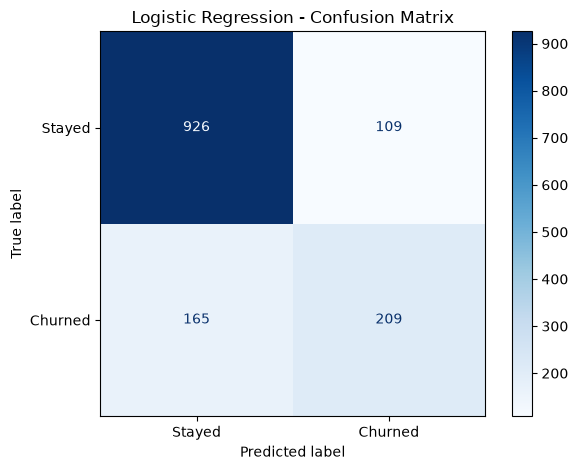

Confusion matrix:
[[926 109]
 [165 209]]


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Predictions from both models
lr_pred = logistic_model.predict(X_test)
lr_prob = logistic_model.predict_proba(X_test)[:, 1]

rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Compare performance
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, lr_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, lr_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, lr_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, lr_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

display(results.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.806,0.657,0.559,0.604,0.842
1,Random Forest,0.770,0.559,0.634,0.594,0.823


In [24]:
from pathlib import Path
import joblib
import json

# Get project root
project_root = Path.cwd().parent

# Create models folder if needed
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Save the trained pipeline
model_path = models_dir / "churn_model.joblib"
joblib.dump(logistic_model, model_path)

print("Model saved successfully!")
print("Saved at:", model_path)

Model saved successfully!
Saved at: d:\Python\DSFROMSCRATCH\Day 16\customer-churn-prediction\models\churn_model.joblib


In [25]:
# Save model comparison results
results_path = project_root / "reports" / "model_comparison.json"
results_path.parent.mkdir(parents=True, exist_ok=True)

results_dict = results.set_index("Model").round(4).to_dict(
    orient="index"
)

with open(results_path, "w", encoding="utf-8") as file:
    json.dump(results_dict, file, indent=4)

print("Evaluation results saved at:", results_path)

Evaluation results saved at: d:\Python\DSFROMSCRATCH\Day 16\customer-churn-prediction\reports\model_comparison.json


In [26]:
# Load the saved model
loaded_model = joblib.load(model_path)

# Predict on the test dataset
saved_predictions = loaded_model.predict(X_test)

# Confirm predictions match the original model
import numpy as np

print(
    "Predictions match:",
    np.array_equal(y_pred, saved_predictions)
)

print("Sample predictions:", saved_predictions[:10])

Predictions match: True
Sample predictions: [0 1 0 0 0 1 0 0 0 0]
